# Tarea 2 — Regresión lineal simple y múltiple

**Objetivo.** Predecir la resistencia a compresión del concreto (`resistencia_mpa`) a partir de sus componentes y edad. Se contrasta una regresión simple que usa cemento con una regresión múltiple que usa todos los predictores.

Se separa 80% para entrenamiento y 20% para prueba. La evaluación final se hace en observaciones no usadas para ajustar los modelos.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

candidatos = [Path("Concrete_Data.csv"), Path("../../Concrete_Data.csv"), Path("../Concrete_Data.csv")]
archivo = next((p for p in candidatos if p.exists()), None)
if archivo is None:
    raise FileNotFoundError("No se encontró Concrete_Data.csv; abre el notebook desde una carpeta del proyecto.")
nombres = ["cemento", "escoria", "ceniza_volante", "agua", "superplastificante",
           "agregado_grueso", "agregado_fino", "edad_dias", "resistencia_mpa"]
datos = pd.read_csv(archivo)
datos.columns = nombres
print("Dimensiones:", datos.shape)
datos.describe().T.round(2)

Dimensiones: (1030, 9)


,count,mean,std,min,25%,50%,75%,max
cemento,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
escoria,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
ceniza_volante,1030.0,54.19,64.00,0.00,0.00,0.00,118.27,200.1
agua,1030.0,181.57,21.36,121.75,164.90,185.00,192.00,247.0
superplastificante,1030.0,6.20,5.97,0.00,0.00,6.35,10.16,32.2
agregado_grueso,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
agregado_fino,1030.0,773.58,80.18,594.00,730.95,779.51,824.00,992.6
edad_dias,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
resistencia_mpa,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


## División entrenamiento/prueba y métricas

Entrenamiento: 824 Prueba: 206
Correlación de Pearson en entrenamiento: PearsonRResult(statistic=np.float64(0.49668805073013805), pvalue=np.float64(1.5162138837828656e-52))
Intercepto simple: 13.785457525758371
Pendiente simple: 0.07789518511382497
cemento               0.118975
escoria               0.108518
ceniza_volante        0.082169
agua                 -0.135712
superplastificante    0.308732
agregado_grueso       0.017804
agregado_fino         0.024061
edad_dias             0.116444
dtype: float64


,RMSE (MPa),MAE (MPa),R²
Simple: cemento,13.885,11.556,0.252
Múltiple: todos,9.797,7.745,0.628


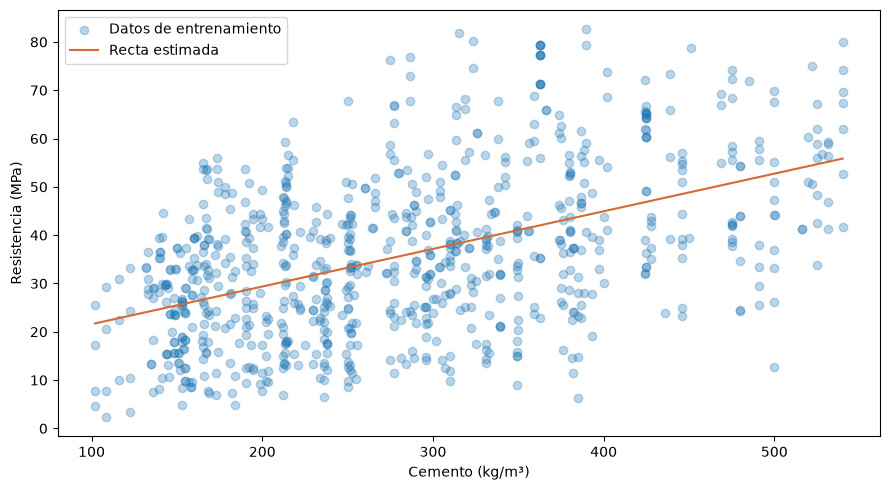

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

variables = nombres[:-1]
train, test = train_test_split(datos, test_size=0.2, random_state=42)
y_train, y_test = train.resistencia_mpa, test.resistencia_mpa
modelo_simple = LinearRegression().fit(train[["cemento"]], y_train)
modelo_multiple = LinearRegression().fit(train[variables], y_train)
pred_simple = modelo_simple.predict(test[["cemento"]])
pred_multiple = modelo_multiple.predict(test[variables])
print("Entrenamiento:", len(train), "Prueba:", len(test))
print("Correlación de Pearson en entrenamiento:", pearsonr(train.cemento, y_train))
print("Intercepto simple:", modelo_simple.intercept_)
print("Pendiente simple:", modelo_simple.coef_[0])
print(pd.Series(modelo_multiple.coef_, index=variables))
def metricas(y, pred):
    return {"RMSE (MPa)": np.sqrt(mean_squared_error(y,pred)),
            "MAE (MPa)": mean_absolute_error(y,pred), "R²": r2_score(y,pred)}
display(pd.DataFrame([metricas(y_test,pred_simple), metricas(y_test,pred_multiple)],
                     index=["Simple: cemento", "Múltiple: todos"]).round(3))
fig, ax = plt.subplots(figsize=(9,5))
ax.scatter(train.cemento, y_train, alpha=.3, label="Datos de entrenamiento")
x = np.linspace(train.cemento.min(), train.cemento.max(), 100)
ax.plot(x, modelo_simple.predict(pd.DataFrame({"cemento":x})), color="#d56b32", label="Recta estimada")
ax.set(xlabel="Cemento (kg/m³)", ylabel="Resistencia (MPa)")
ax.legend(); plt.tight_layout(); plt.show()

## Interpretación y diagnósticos

El coeficiente de cemento en el modelo simple describe su asociación lineal sin controlar por los otros componentes. En el modelo múltiple, cada coeficiente se interpreta manteniendo fijas las demás variables. Los coeficientes y métricas describen esta muestra y no prueban causalidad.

In [3]:
residuos = y_test - pred_multiple
print("Media de residuos en prueba:", round(float(residuos.mean()), 4))
print("Correlación observación-predicción:", round(float(np.corrcoef(y_test, pred_multiple)[0, 1]), 4))
for real, estimado in zip(y_test[:8], pred_multiple[:8]):
    print(f"Real: {real:6.2f} MPa | Predicción: {estimado:6.2f} MPa | Residuo: {real-estimado:6.2f}")

Media de residuos en prueba: 0.018
Correlación observación-predicción: 0.7923
Real:  52.91 MPa | Predicción:  59.66 MPa | Residuo:  -6.75
Real:  55.90 MPa | Predicción:  52.04 MPa | Residuo:   3.86
Real:  74.50 MPa | Predicción:  63.52 MPa | Residuo:  10.98
Real:  35.30 MPa | Predicción:  51.57 MPa | Residuo: -16.27
Real:  10.54 MPa | Predicción:  17.22 MPa | Residuo:  -6.68
Real:  44.28 MPa | Predicción:  39.87 MPa | Residuo:   4.42
Real:  23.69 MPa | Predicción:  26.70 MPa | Residuo:  -3.01
Real:  45.37 MPa | Predicción:  44.72 MPa | Residuo:   0.65


## Predicción de una mezcla nueva

La composición debe estar en las mismas unidades y orden que la base. La predicción puntual no sustituye pruebas de laboratorio.

In [4]:
mezcla = pd.DataFrame([{
    "cemento": 350, "escoria": 100, "ceniza_volante": 0, "agua": 180,
    "superplastificante": 8, "agregado_grueso": 1000,
    "agregado_fino": 750, "edad_dias": 28,
}])
prediccion = float(modelo_multiple.predict(mezcla[variables])[0])
print(f"Resistencia estimada: {prediccion:.2f} MPa")

Resistencia estimada: 41.01 MPa
